# Titanium EBSD Boundary Map from TSL Grain and Boundary Files

This example imports the supplied **MPIE Ti-alloy reconstructed EBSD data**:

- `MPIE_Ti_alloy_GF2_RDdownTDright.txt`: grain IDs, average Bunge Euler angles, centers, and phases.
- `MPIE_Ti_alloy_RB_RDdownTDright.txt`: reconstructed boundary endpoints and neighboring grain IDs.

The plot uses the **exported boundary network directly**, not a new pixel-based reconstruction. Boundary colors show the maximum Luster-Morris geometric compatibility parameter:

$$m'_{\max}=\max_{i,j}\left| (\mathbf{n}_i\cdot\mathbf{n}_j)(\mathbf{d}_i\cdot\mathbf{d}_j)\right|.$$

Phase 1 is **alpha titanium (HCP)** with basal and first-order prismatic `<a>` slip (six systems). Phase 2 is **beta titanium (BCC)** with `{110}<111>` slip (12 systems). HCP-HCP and HCP-BCC boundaries are included. These choices do not include pyramidal slip or twins; a geometric maximum does not identify active slip under load.

The files do not contain raw pixel orientations or grain polygons, so this is a **reconstructed boundary map**, not an IPF-colored raster. Dots mark grain centers and phases. TD points right and RD points down, matching the MATLAB display.

## 1. Set Up

Select a Python kernel with NumPy, SciPy, and Matplotlib installed, then run all cells. The calculation reuses `ebsd_mprime.py`.

In [4]:
%matplotlib inline

from importlib import reload
from pathlib import Path
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy

python_dir = next(
    (candidate.resolve() for candidate in (Path.cwd(), Path.cwd() / "python")
     if (candidate / "ebsd_mprime.py").is_file()),
    None,
)
if python_dir is None:
    raise FileNotFoundError("Open this notebook from the STABiX root or its python folder.")
if str(python_dir) not in sys.path:
    sys.path.insert(0, str(python_dir))

import ebsd_mprime
reload(ebsd_mprime)
from ebsd_mprime import (
    plot_reconstructed_map, read_tsl_reconstruction, reconstructed_mprime,
)

print(f"Python {sys.version.split()[0]}")
print(f"NumPy {np.__version__} | SciPy {scipy.__version__} | Matplotlib {matplotlib.__version__}")

Python 3.14.4
NumPy 2.4.4 | SciPy 1.17.1 | Matplotlib 3.10.8


## 2. Import Grain Averages and Reconstructed Boundaries

The data folder is resolved relative to the repository: `gui_ebsd_map/ebsd_dataExamples`.

Following MATLAB's `interface_map_init_microstructure.m` and `interface_map_mprime_calculator_map.m`:

| Export | Columns (1-based) | Imported quantity |
| --- | --- | --- |
| GF2 | 1 | Original grain ID |
| GF2 | 2-4 | Average Bunge Euler angles in **degrees** |
| GF2 | 5-6 | Grain center X, Y in micrometers |
| GF2 | 10 | Phase: 1 = HCP alpha, 2 = BCC beta |
| RB | 7 | Exported segment length in micrometers |
| RB | 9-12 | Exact segment endpoints X1, Y1, X2, Y2 |
| RB | 13-14 | Adjacent grain IDs, joined to GF2 IDs |

RB columns 1-6 contain redundant rounded Euler angles in **radians**. The calculation uses GF2 orientations, as MATLAB does, without mixing angle units. Missing/duplicate grain IDs are rejected. Reversed grain-pair order is canonicalized, so all segments for a pair share one value.

The Cartesian HCP vectors follow the first six systems in `crystallo/slip_systems.m` and the conversions in `millerbravaisdir2cart.m` and `millerbravaisplane2cart.m`. No c/a choice is needed for basal/prismatic `<a>` directions and normals. Crystal-to-sample rotations are the transpose of MATLAB's `eulers2g.m` matrices. MATLAB negates plotted Y; here the Y axis is inverted for the same RD-down display, without altering orientations or swapping X and Y.

In [5]:
data_dir = python_dir.parent / "gui_ebsd_map" / "ebsd_dataExamples"
grain_path = data_dir / "MPIE_Ti_alloy_GF2_RDdownTDright.txt"
boundary_path = data_dir / "MPIE_Ti_alloy_RB_RDdownTDright.txt"
phase_structures = {1: "hcp", 2: "bcc"}

scan = read_tsl_reconstruction(grain_path, boundary_path)
values = reconstructed_mprime(scan, phase_structures)
phase_pairs = np.sort(scan.phases[scan.pairs], axis=1)

assert np.all(np.isfinite(values))
assert np.all((values >= 0) & (values <= 1))
print(f"Grain file: {grain_path.name}")
print(f"Boundary file: {boundary_path.name}")
print(f"Imported grains: {len(scan.grain_ids)}")
for phase_id, structure_name in phase_structures.items():
    print(f"  Phase {phase_id} ({structure_name.upper()}): {np.count_nonzero(scan.phases == phase_id)} grains")
print(f"Imported boundary segments: {len(scan.segments)}")
print(f"Unique neighboring grain pairs: {len(scan.pairs)}")
for phase_combination in np.unique(phase_pairs, axis=0):
    selected = np.all(phase_pairs == phase_combination, axis=1)
    print(f"  Phases {phase_combination.tolist()}: {np.count_nonzero(selected)} pairs")
print(f"Maximum m-prime range: {values.min():.4f} to {values.max():.4f}")

Grain file: MPIE_Ti_alloy_GF2_RDdownTDright.txt
Boundary file: MPIE_Ti_alloy_RB_RDdownTDright.txt
Imported grains: 430
  Phase 1 (HCP): 429 grains
  Phase 2 (BCC): 1 grains
Imported boundary segments: 2813
Unique neighboring grain pairs: 1196
  Phases [1, 1]: 1194 pairs
  Phases [1, 2]: 2 pairs
Maximum m-prime range: 0.6218 to 0.9987


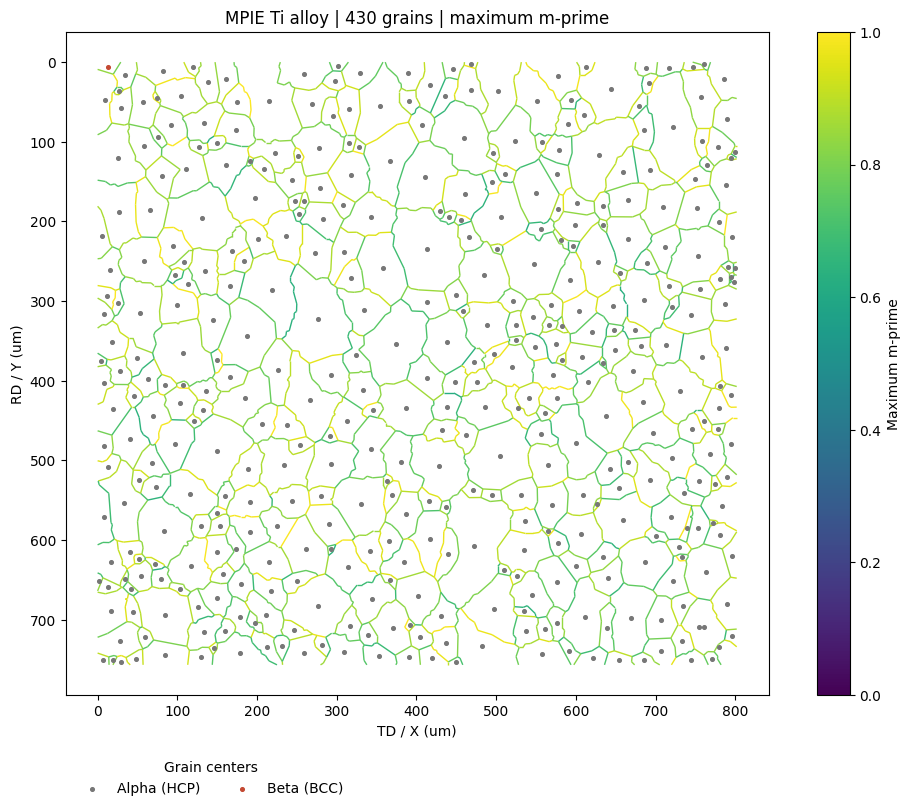

In [6]:
figure = plot_reconstructed_map(
    scan, values,
    title=f"MPIE Ti alloy | {len(scan.grain_ids)} grains | maximum m-prime",
)
plt.show()

## Additional slip-transmission boundary maps

The maps below use the same GF2 grain orientations, RB boundaries, and basal/Prism1 HCP and {110} BCC slip systems as the m-prime map. Each boundary segment receives the value for its grain pair; grain interiors are not colored.

- **Maximum |N|**: maximum absolute Livingston-Chalmers N factor over slip-system pairs.
- **Signed N at maximum |N|**: the signed matrix entry with the largest absolute value. Its sign depends on the chosen slip-system vector signs and on tie ordering; it is not an independent transmission prediction.
- **Minimum residual Burgers vector** and **residual at maximum m-prime**: bidirectional minimum of |bA-bB| and |bA+bB|, in nm. The smallest residual need not occur at the m-prime-maximizing pair.

For alpha-alpha boundaries, an illustrative Burgers magnitude of 0.298 nm is used. Interphase and beta-beta residuals are undefined because a beta magnitude was not supplied, and their boundary segments are left uncolored. These quantities describe geometry, not measured slip activation or transmission.

Residuals undefined for 2 grain pairs.


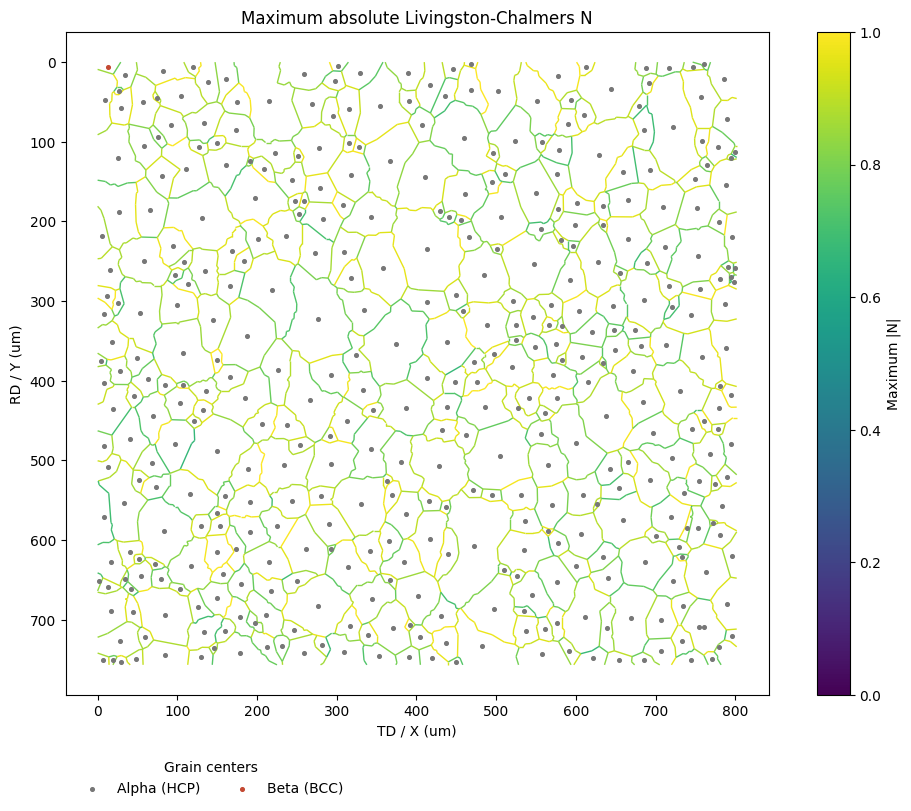

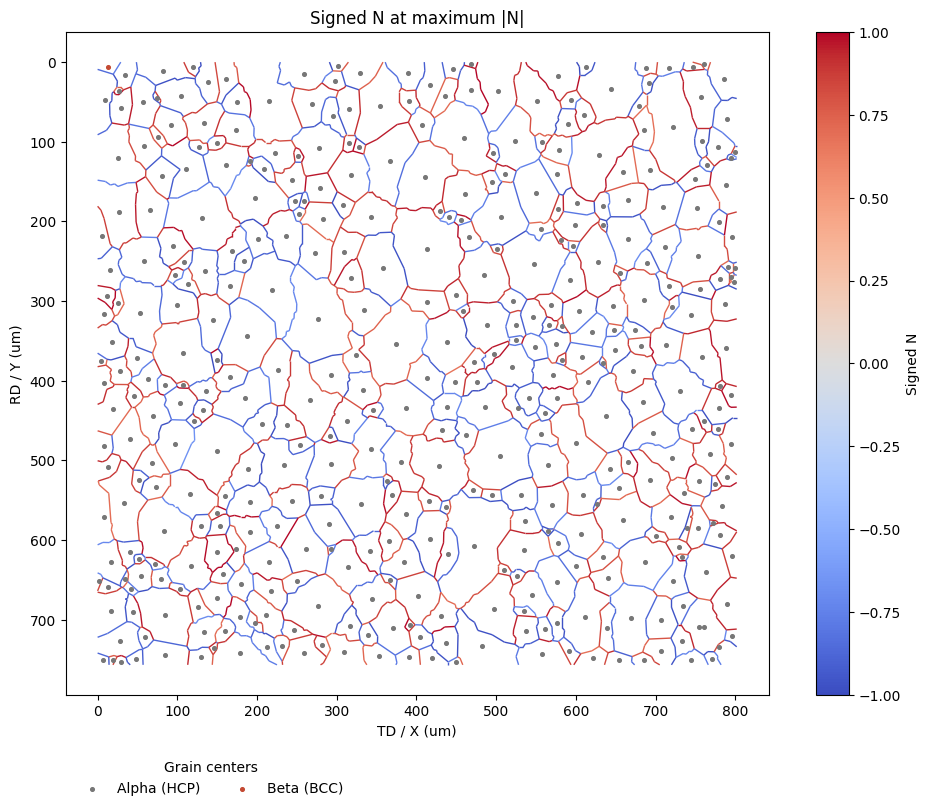

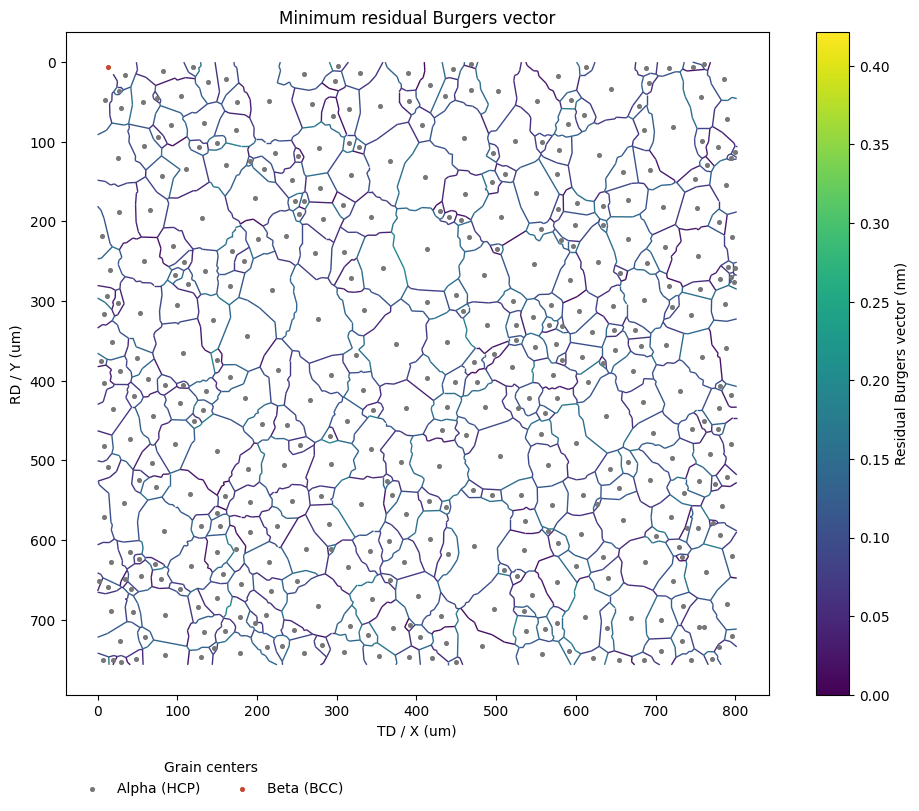

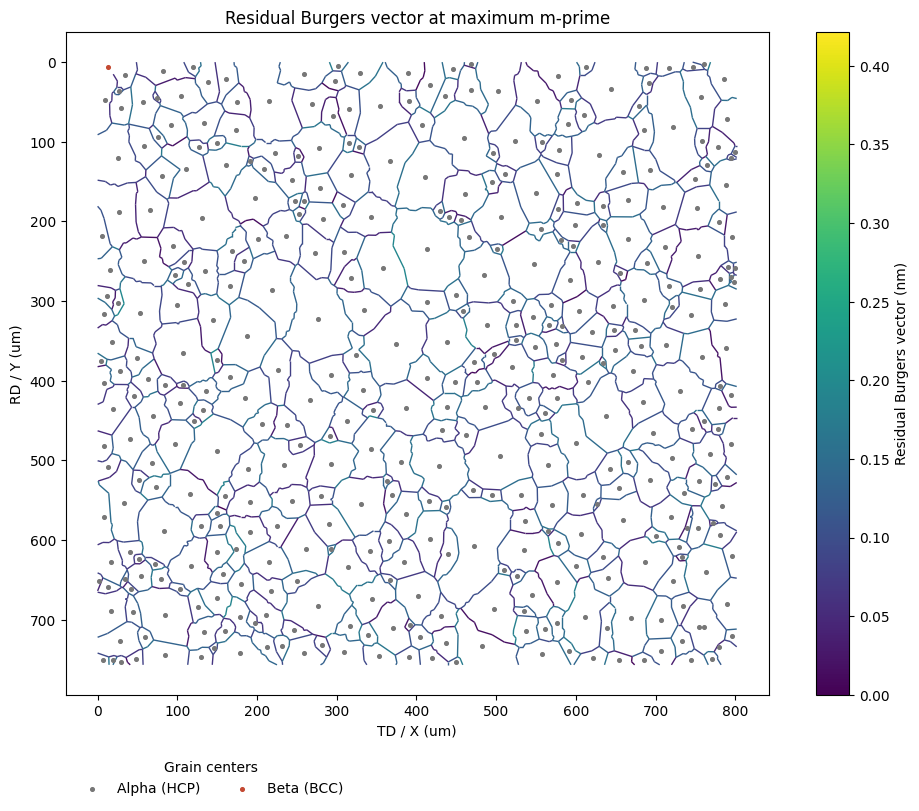

In [7]:
from IPython.display import display
import experimental_descriptors as descriptors
reload(descriptors)
reload(ebsd_mprime)

phase_systems = {phase: ebsd_mprime.slip_systems(structure)
                 for phase, structure in phase_structures.items()}
burgers_alpha_nm = 0.298
metric_values = {name: np.empty(len(scan.pairs)) for name in (
    "max_abs_N", "signed_N_at_max_abs", "min_residual_burgers_nm",
    "residual_at_max_mprime_nm",
)}
for pair_index, (first, second) in enumerate(scan.pairs):
    phase_a, phase_b = int(scan.phases[first]), int(scan.phases[second])
    alpha_pair = phase_a == phase_b == 1
    result = descriptors.slip_pair_descriptors(
        scan.eulers[first], scan.eulers[second], phase_systems[phase_a], phase_systems[phase_b],
        burgers_a_nm=burgers_alpha_nm if alpha_pair else None,
        burgers_b_nm=burgers_alpha_nm if alpha_pair else None,
    )
    n_matrix = result["N_signed_matrix"]
    metric_values["signed_N_at_max_abs"][pair_index] = n_matrix.flat[np.abs(n_matrix).argmax()]
    for name in ("max_abs_N", "min_residual_burgers_nm", "residual_at_max_mprime_nm"):
        metric_values[name][pair_index] = result[name]

map_specs = (
    ("max_abs_N", "Maximum absolute Livingston-Chalmers N", "Maximum |N|", "viridis", 0, 1),
    ("signed_N_at_max_abs", "Signed N at maximum |N|", "Signed N", "coolwarm", -1, 1),
    ("min_residual_burgers_nm", "Minimum residual Burgers vector", "Residual Burgers vector (nm)", "viridis", 0, np.sqrt(2) * burgers_alpha_nm),
    ("residual_at_max_mprime_nm", "Residual Burgers vector at maximum m-prime", "Residual Burgers vector (nm)", "viridis", 0, np.sqrt(2) * burgers_alpha_nm),
)
print(f"Residuals undefined for {np.isnan(metric_values['min_residual_burgers_nm']).sum()} grain pairs.")
for name, title, label, cmap, vmin, vmax in map_specs:
    metric_figure = ebsd_mprime.plot_reconstructed_map(
        scan, metric_values[name], title=title, cmap=cmap,
        vmin=vmin, vmax=vmax, colorbar_label=label,
    )
    display(metric_figure)
    plt.close(metric_figure)

## 3. Distribution Across Grain Pairs

The histogram counts each neighboring grain pair **once**, regardless of boundary length. High maximum m-prime indicates a geometrically well-aligned slip-system pair, but does not establish that the pair is active.

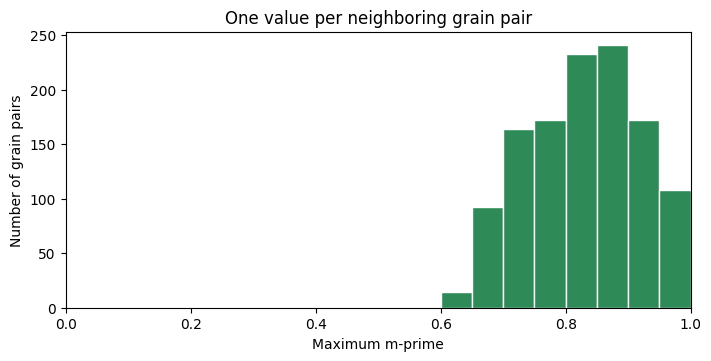

In [8]:
histogram, axes = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
axes.hist(values, bins=np.linspace(0, 1, 21), color="seagreen", edgecolor="white")
axes.set(
    xlabel="Maximum m-prime", ylabel="Number of grain pairs",
    xlim=(0, 1), title="One value per neighboring grain pair",
)
plt.show()

## 4. Inspect the Lowest-Compatibility Grain Pairs

These are the ten smallest **maximum** m-prime values for the chosen slip families, not the minimum over slip systems. IDs are the original GF2 grain IDs. Total boundary length is the sum of the RB column-7 lengths for each pair, not a histogram weight.

In [9]:
pair_lengths = np.bincount(
    scan.segment_pairs, weights=scan.boundary_lengths, minlength=len(scan.pairs),
)
print(f"{'Grain A':>8} {'Grain B':>8} {'Phases':>10} {'Max m-prime':>13} {'Length (um)':>13}")
for pair_index in np.argsort(values)[:10]:
    first, second = scan.pairs[pair_index]
    phase_label = f"{scan.phases[first]} / {scan.phases[second]}"
    print(
        f"{scan.grain_ids[first]:8d} {scan.grain_ids[second]:8d} {phase_label:>10} "
        f"{values[pair_index]:13.4f} {pair_lengths[pair_index]:13.2f}"
    )

 Grain A  Grain B     Phases   Max m-prime   Length (um)
     219      240      1 / 1        0.6218         23.40
     151      160      1 / 1        0.6225          8.52
      96      120      1 / 1        0.6281         10.25
     153      162      1 / 1        0.6304         42.20
     350      355      1 / 1        0.6315         16.35
      48       66      1 / 1        0.6329         12.68
     143      148      1 / 1        0.6386        104.21
     180      203      1 / 1        0.6409         28.29
     338      343      1 / 1        0.6439         17.00
     239      248      1 / 1        0.6444         51.57


## Residual Burgers vector: Patriarca (2013) reference check

The 12 BCC cases in `gui_bicrystal/gui_bicrystal_data/patriarca_2013` specify Euler angles, selected slip directions, and reference residuals (DOI: 10.1016/j.msea.2013.08.050). Following the repository's MATLAB example, we rotate the selected unnormalized directions into the sample frame, choose the smaller of the sum and difference, and divide by two. Values are in lattice-parameter units, not nm. This is a selected-slip comparison, not the minimum over all slip systems used in the map.

The tolerance is 0.0051, reflecting two-decimal reference rounding. These are repository transcriptions, not independently verified paper values. Cases 5 and 6 remain discrepant; the historic `Data_Patriarca2013.txt` also differs from current-input calculations for cases 8 and 9.

In [10]:
import literature_checks
reload(literature_checks)
patriarca_dir = python_dir.parent / "gui_bicrystal" / "gui_bicrystal_data" / "patriarca_2013"
patriarca_results = literature_checks.patriarca_residual_comparison(patriarca_dir)
print(f"{'Case':>4} {'Grains':>9} {'Reference':>10} {'Calculated':>11} {'Error':>9} {'Check':>8}")
for row in patriarca_results:
    grains = f"{row['grain_a']}/{row['grain_b']}"
    check = "OK" if row['within_tolerance'] else "MISMATCH"
    print(f"{row['number']:4d} {grains:>9} {row['reference']:10.2f} {row['calculated']:11.6f} {row['absolute_error']:9.6f} {check:>8}")
print(f"Agreement: {sum(row['within_tolerance'] for row in patriarca_results)}/{len(patriarca_results)} cases")

Case    Grains  Reference  Calculated     Error    Check
   1       1/2       0.16    0.157582  0.002418       OK
   2       3/2       1.07    1.072573  0.002573       OK
   3       2/4       0.38    0.380954  0.000954       OK
   4       2/6       0.28    0.284339  0.004339       OK
   5       2/7       1.28    1.168134  0.111866 MISMATCH
   6       2/8       1.31    1.138499  0.171501 MISMATCH
   7       3/4       1.14    1.141881  0.001881       OK
   8       4/5       1.14    1.139595  0.000405       OK
   9       5/6       0.64    0.635935  0.004065       OK
  10       7/8       0.07    0.068262  0.001738       OK
  11       7/6       0.18    0.175050  0.004950       OK
  12       6/4       0.94    0.944762  0.004762       OK
Agreement: 10/12 cases


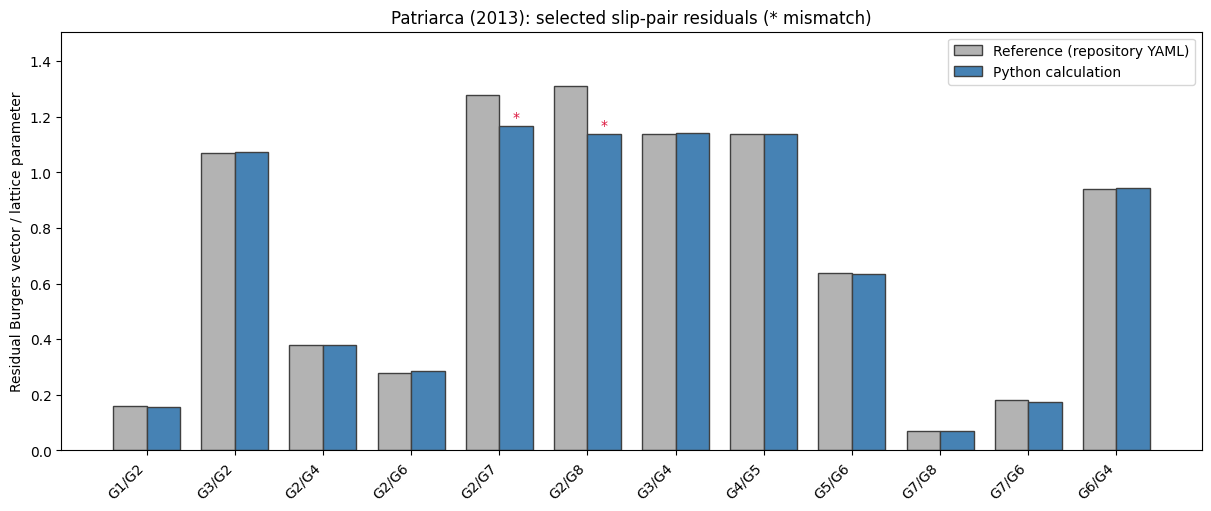

In [11]:
case_positions = np.arange(len(patriarca_results))
grain_labels = [f"G{row['grain_a']}/G{row['grain_b']}" for row in patriarca_results]
reference_values = [row['reference'] for row in patriarca_results]
calculated_values = [row['calculated'] for row in patriarca_results]

patriarca_figure, patriarca_axes = plt.subplots(figsize=(12, 5), constrained_layout=True)
width = 0.38
patriarca_axes.bar(case_positions - width / 2, reference_values, width,
                   color="0.7", edgecolor="0.25", label="Reference (repository YAML)")
calculated_bars = patriarca_axes.bar(case_positions + width / 2, calculated_values, width,
                                      color="steelblue", edgecolor="0.25", label="Python calculation")
for row, bar in zip(patriarca_results, calculated_bars):
    if not row['within_tolerance']:
        patriarca_axes.annotate("*", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                                xytext=(0, 3), textcoords="offset points", ha="center", color="crimson")
patriarca_axes.set_xticks(case_positions, grain_labels, rotation=45, ha="right")
patriarca_axes.set(ylabel="Residual Burgers vector / lattice parameter",
                   title="Patriarca (2013): selected slip-pair residuals (* mismatch)")
patriarca_axes.set_ylim(0, max(max(reference_values), max(calculated_values)) * 1.15)
patriarca_axes.legend()
plt.show()

## 5. Literature Cross-Checks: Guo et al. (2014)

The repository contains seven Table 3 bicrystals in `gui_bicrystal/gui_bicrystal_data/guo_2014` (DOI: https://doi.org/10.1016/j.actamat.2014.05.015). The next cell reads their **stored Euler angles and reference m-prime values** directly from YAML; the original publication has not been independently re-transcribed here.

The comparison follows `Guo2014_Table3_mprime_plot.m` exactly. Its matrix rows correspond to grain B and columns to grain A:

- `mprime_pripri`: A prismatic / B prismatic, MATLAB block `(4:6, 4:6)`.
- `mprime_pribas`: **A basal / B prismatic**, MATLAB block `(4:6, 1:3)`.

Each block is maximized over its 3 x 3 system pairs. This is not the maximum over the combined basal/prismatic set used for the EBSD map. Pyramidal `<a>` and `<c+a>` references are **not checked**, because those families are not implemented.

The fixed tolerance is **0.0051**: half the two-decimal reference precision plus 0.0001 for rounded input orientations. Mismatches remain visible; the tolerance is not fitted to the results. Independent tests compare the Python outputs against explicitly constructed matrices from MATLAB's Bunge formulas, rather than executing MATLAB itself.

In [12]:
from importlib import reload
import ebsd_mprime
reload(ebsd_mprime)

literature_dir = python_dir.parent / "gui_bicrystal" / "gui_bicrystal_data" / "guo_2014"
literature_results = ebsd_mprime.guo_literature_comparison(literature_dir)

print(f"{'Case':<7} {'A family / B family':<29} {'Stored':>8} {'Python':>10} {'Abs. error':>11} {'Check':>10}")
for result in literature_results:
    case_name = result["case"].removeprefix("Guo2014_Table3")
    status = "PASS" if result["within_tolerance"] else "MISMATCH"
    print(
        f"{case_name:<7} {result['comparison']:<29} {result['reference']:8.2f} "
        f"{result['calculated']:10.6f} {result['absolute_error']:11.6f} {status:>10}"
    )
agreeing = sum(result["within_tolerance"] for result in literature_results)
print(f"\nWithin fixed rounding tolerance: {agreeing}/{len(literature_results)} comparisons.")
print("Mismatch does not establish a Python bug or a source-data error; these require further investigation.")

Case    A family / B family             Stored     Python  Abs. error      Check
Case1   A prismatic / B prismatic         0.94   0.942363    0.002363       PASS
Case1   A basal / B prismatic             0.04   0.078742    0.038742   MISMATCH
Case2   A prismatic / B prismatic         0.46   0.469671    0.009671   MISMATCH
Case2   A basal / B prismatic             0.71   0.710370    0.000370       PASS
Case3   A prismatic / B prismatic         0.95   0.949079    0.000921       PASS
Case3   A basal / B prismatic             0.19   0.180458    0.009542   MISMATCH
Case4   A prismatic / B prismatic         0.41   0.411775    0.001775       PASS
Case4   A basal / B prismatic             0.64   0.800355    0.160355   MISMATCH
Case5   A prismatic / B prismatic         0.84   0.841257    0.001257       PASS
Case5   A basal / B prismatic             0.45   0.459866    0.009866   MISMATCH
Case6   A prismatic / B prismatic         0.73   0.746922    0.016922   MISMATCH
Case6   A basal / B prismati

## 6. Reproduce the Supplied Prismatic-Prismatic Comparison

The supplied figure shows **Prism1<a> to Prism1<a> family maxima only** (MATLAB systems 4-6 in both grains), not the separate basal-prismatic comparison. Python reproduces all seven displayed MATLAB values after rounding to two decimal places:

| Bicrystal | Guo reference | MATLAB labels in supplied figure / Python rounded |
| --- | --- | --- |
| 1 | 0.94 | 0.94 |
| 2 | 0.46 | 0.47 |
| 3 | 0.95 | 0.95 |
| 4 | 0.41 | 0.41 |
| 5 | 0.84 | 0.84 |
| 6 | 0.73 | 0.75 |
| 7 | 0.91 | 0.91 |

Thus the Case 2 and Case 6 differences from the stored paper values are already present in the supplied MATLAB figure; they are **not Python-only discrepancies**. The stricter rounding checks in the preceding table remain useful but do not mean Python fails to reproduce this figure. The larger basal-prismatic differences concern another observable not shown here.

The plot below uses the YAML reference values and **unrounded Python calculations** for bar heights. Labels are rounded only for display. It is not a new MATLAB execution.

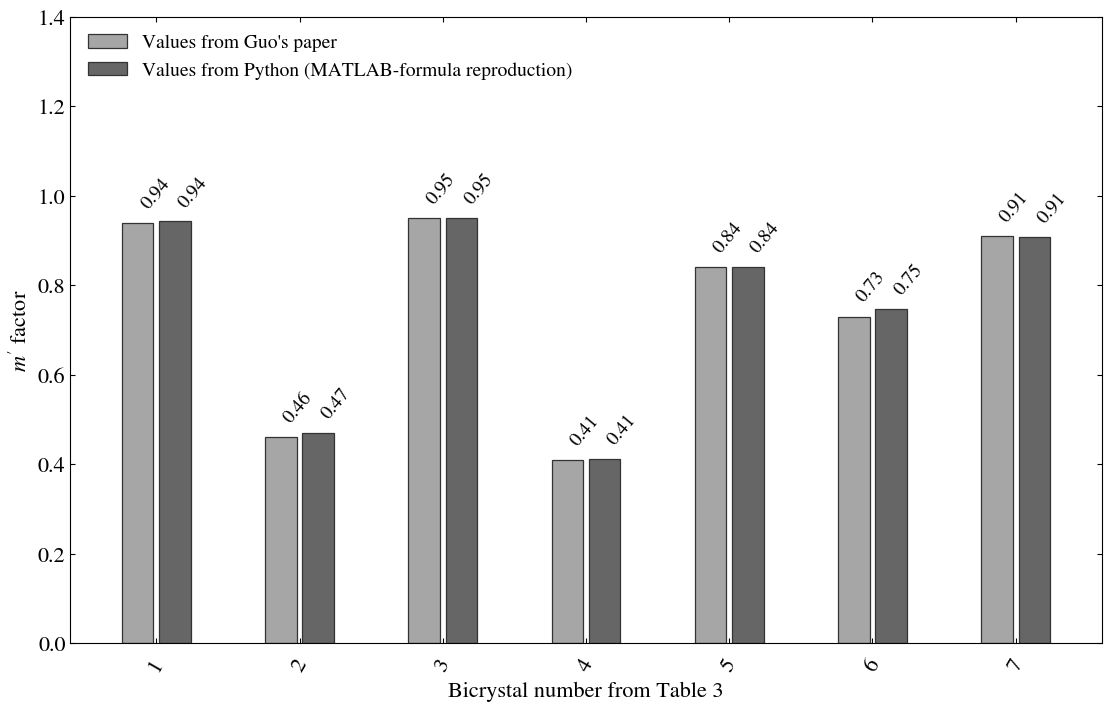

All seven rounded Python values match the MATLAB labels in the supplied figure.
Saved C:\github\stabix\python\guo2014_prismatic_comparison.png


In [13]:
prismatic_results = [
    result for result in literature_results
    if result["comparison"] == "A prismatic / B prismatic"
]
case_numbers = np.array([
    int(result["case"].removeprefix("Guo2014_Table3Case")) for result in prismatic_results
])
paper_values = np.array([result["reference"] for result in prismatic_results])
python_values = np.array([result["calculated"] for result in prismatic_results])
matlab_figure_labels = np.array([0.94, 0.47, 0.95, 0.41, 0.84, 0.75, 0.91])
np.testing.assert_array_equal(case_numbers, np.arange(1, 8))
np.testing.assert_array_equal(np.round(python_values, 2), matlab_figure_labels)

with plt.rc_context({"font.family": "STIXGeneral", "font.size": 16, "mathtext.fontset": "stix"}):
    literature_figure, literature_axes = plt.subplots(figsize=(11, 7), constrained_layout=True)
    width = 0.22
    paper_bars = literature_axes.bar(
        case_numbers - 0.13, paper_values, width,
        color="0.65", edgecolor="0.2", linewidth=0.9, label="Values from Guo's paper",
    )
    python_bars = literature_axes.bar(
        case_numbers + 0.13, python_values, width,
        color="0.40", edgecolor="0.2", linewidth=0.9,
        label="Values from Python (MATLAB-formula reproduction)",
    )
    for bars in (paper_bars, python_bars):
        for bar in bars:
            literature_axes.text(
                bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.025,
                f"{bar.get_height():.2f}", rotation=50, ha="left", va="bottom", fontsize=14,
            )
    literature_axes.set(
        xlabel="Bicrystal number from Table 3", ylabel=r"$m'$ factor",
        xticks=case_numbers, xlim=(0.4, 7.6), ylim=(0, 1.4),
        yticks=np.arange(0, 1.41, 0.2),
    )
    literature_axes.tick_params(direction="in", top=True, right=True)
    literature_axes.tick_params(axis="x", labelrotation=60, pad=9)
    literature_axes.legend(loc="upper left", frameon=False, fontsize=14)
    comparison_path = python_dir / "guo2014_prismatic_comparison.png"
    literature_figure.savefig(comparison_path, dpi=180)
    plt.show()

print("All seven rounded Python values match the MATLAB labels in the supplied figure.")
print(f"Saved {comparison_path}")

## Save and Interpretation

The prismatic-prismatic comparison is saved as `guo2014_prismatic_comparison.png` in this folder. To save the imported Ti-alloy map, run `figure.savefig(python_dir / "ti_alloy_mprime.png", dpi=200)` in a new code cell.

This map uses the original exported boundary segments, without additional smoothing or grain reconstruction. A pair's maximum is evaluated across six HCP basal/Prism1 systems and/or 12 BCC systems, depending on its phases. Other slip-family choices would change these values; HCP pyramidal slip and twins are not implemented. Interface values are geometric comparisons, not predictions of interface slip transmission. `hcp_prismatic1` and `hcp_prismatic2` distinguish the two prismatic families listed by MATLAB; the Guo figure uses Prism1.

The MATLAB sources guiding the import and convention are `gui_ebsd_map/interface_map_init_microstructure.m`, `gui_ebsd_map/interface_map_mprime_calculator_map.m`, `crystallo/slip_systems.m`, and the Miller-Bravais conversion functions. The CLI's separate CTF workflow still supports cubic pixel scans only.

**Figure reproduction:** all seven rounded Python prismatic-prismatic values match the MATLAB labels in the supplied image. The 0.46/0.47 difference for Case 2 and 0.73/0.75 difference for Case 6 are already present in that image, not Python-only discrepancies.

**Extended literature checks:** the preceding 14-comparison table also includes basal-prismatic blocks not shown in the image. At a fixed tolerance of 0.0051, 6 of those 14 stored paper values agree; that strict criterion is distinct from reproducing the MATLAB figure. Norms, signs, valid angle wrapping, HCP symmetry, and four-decimal input rounding do not explain the larger basal-prismatic differences. Selected-slip versus family-maximum comparisons remain a possible explanation, not a confirmed interpretation of the original paper. MATLAB itself was not executed and the source YAML values were not changed. PyYAML, listed in `requirements.txt`, is required to read the literature cases.

See [README.md](README.md) for supported formats and tests. Luster and Morris (1995): https://doi.org/10.1007/BF02670762.